In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
import sklearn.model_selection
import sklearn.ensemble
import sklearn.metrics
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

Task 1: Data Acquisition and Exploration


In [20]:
DATA_DIR = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train"

CLASSES = ["NORMAL", "PNEUMONIA"]

In [21]:
image_paths = []
labels = []

class_counts = {}
for label, cls in enumerate(CLASSES):
    cls_dir = os.path.join(DATA_DIR, cls)
    files = os.listdir(cls_dir)
    class_counts[cls] = len(files)
    for file in files:
        image_paths.append((os.path.join(cls_dir, file), label))

print("Class Balance:")
for cls, count in class_counts.items():
    print(f"- {cls}: {count} images")


Class Balance:
- NORMAL: 1341 images
- PNEUMONIA: 3875 images


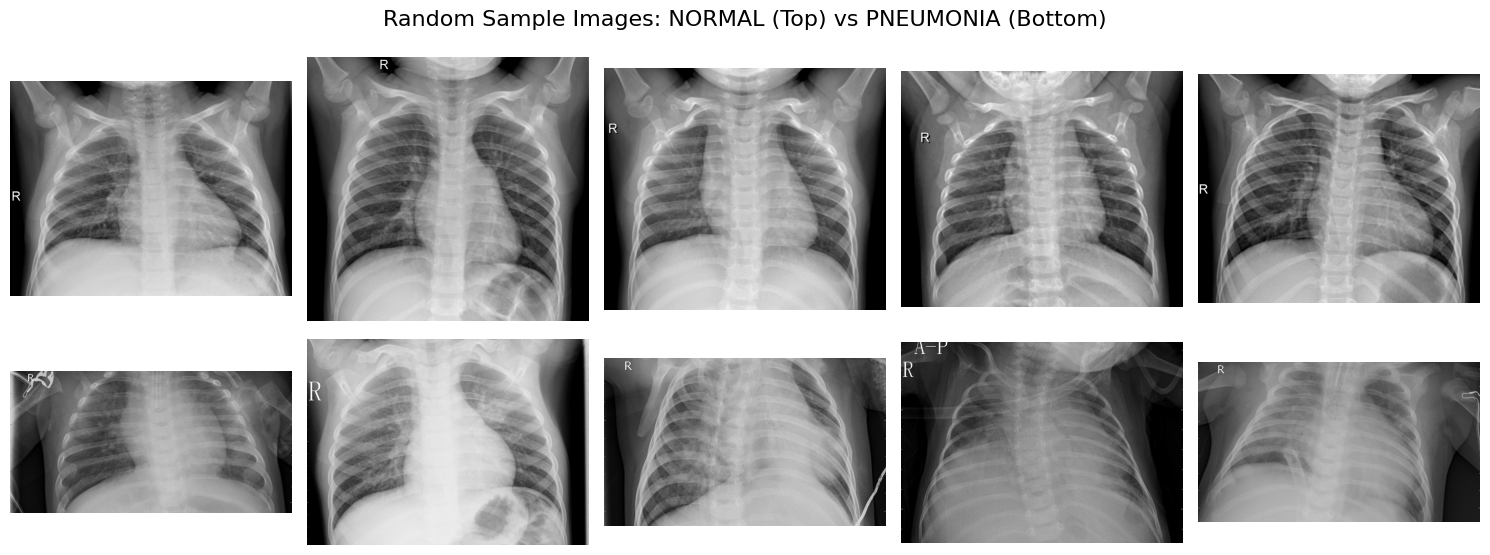

In [22]:
# Shuffle to get random samples
random.shuffle(image_paths)

# Display 5 random samples from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Random Sample Images: NORMAL (Top) vs PNEUMONIA (Bottom)', fontsize=16)

normal_samples = [p for p, l in image_paths if l == 0][:5]
pneumonia_samples = [p for p, l in image_paths if l == 1][:5]

for i in range(5):
    # Plot Normal
    img_n = cv2.imread(normal_samples[i], cv2.IMREAD_GRAYSCALE)
    axes[0, i].imshow(img_n, cmap='gray')
    axes[0, i].axis('off')
    # Plot Pneumonia
    img_p = cv2.imread(pneumonia_samples[i], cv2.IMREAD_GRAYSCALE)
    axes[1, i].imshow(img_p, cmap='gray')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


Task 2: Preprocessing & Feature Extraction

In [23]:
IMG_SIZE = 128

X_images = []    # Raw image arrays for CNN
X_features = []  # Extracted feature vectors (HOG + LBP + GLCM)
y = []           # Labels

print(f"Processing images (Resizing to {IMG_SIZE}x{IMG_SIZE}, Grayscale, Extracting HOG/LBP/GLCM)...")


Processing images (Resizing to 128x128, Grayscale, Extracting HOG/LBP/GLCM)...


In [24]:
for path, label in image_paths:
    # 1. Read as grayscale and resize
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    
    # Store for CNN
    X_images.append(img_resized)
    y.append(label)
    
    # 2. Feature Extraction: HOG (Histogram of Oriented Gradients)
    hog_feat = hog(img_resized, orientations=8, pixels_per_cell=(16, 16),
                   cells_per_block=(1, 1), feature_vector=True)
    
    # 3. Feature Extraction: LBP (Local Binary Patterns)
    lbp = local_binary_pattern(img_resized, P=8, R=1, method='uniform')
    (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, 10), range=(0, 9))
    lbp_feat = hist.astype("float") / (hist.sum() + 1e-7) # Normalize
    
    # 4. Feature Extraction: GLCM (Gray-Level Co-occurrence Matrix)
    glcm = graycomatrix(img_resized, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    glcm_feat = np.array([contrast, correlation])
    
    # Combine extracted features into one vector
    combined_features = np.hstack([hog_feat, lbp_feat, glcm_feat])
    X_features.append(combined_features)

# Convert lists to numpy arrays
X_images = np.array(X_images).reshape(-1, IMG_SIZE, IMG_SIZE, 1) / 255.0 # Normalize for CNN
X_features = np.array(X_features)
y = np.array(y)

print(f"Extraction complete. Image array shape: {X_images.shape}, Feature array shape: {X_features.shape}")


Extraction complete. Image array shape: (5216, 128, 128, 1), Feature array shape: (5216, 523)


In [27]:
# First split: 70% Train, 30% Temp (which will become Val and Test)
X_img_train, X_img_temp, X_feat_train, X_feat_temp, y_train, y_temp = sklearn.model_selection.train_test_split(
    X_images, X_features, y, test_size=0.30, stratify=y, random_state=42
)

# Second split: Split the 30% Temp evenly into 15% Val and 15% Test
X_img_val, X_img_test, X_feat_val, X_feat_test, y_val, y_test = sklearn.model_selection.train_test_split(
    X_img_temp, X_feat_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"Training set: {len(y_train)} samples")
print(f"Validation set: {len(y_val)} samples")
print(f"Testing set: {len(y_test)} samples")

Training set: 3651 samples
Validation set: 782 samples
Testing set: 783 samples


Task 3: Model Training and Evaluation

In [28]:
def build_cnn(learning_rate=0.001):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 1)),
        MaxPooling2D(2, 2),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.5), # Prevent overfitting
        Dense(1, activation='sigmoid') # Binary classification
    ])
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [30]:
print("Training CNN Model")
cnn_model = build_cnn(learning_rate=0.001)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

# 10 epochs with early stopping will easily finish well under 30 minutes on a T4
history = cnn_model.fit(
    X_img_train, y_train, 
    validation_data=(X_img_val, y_val),
    epochs=10, 
    batch_size=32, 
    verbose=1, 
    callbacks=[early_stop]
)


Training CNN Model
Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.8704 - loss: 0.2911 - val_accuracy: 0.9591 - val_loss: 0.1250
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9408 - loss: 0.1522 - val_accuracy: 0.9565 - val_loss: 0.1234
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9521 - loss: 0.1264 - val_accuracy: 0.9668 - val_loss: 0.0917
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9636 - loss: 0.1035 - val_accuracy: 0.9719 - val_loss: 0.0887
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9671 - loss: 0.0969 - val_accuracy: 0.9719 - val_loss: 0.0774
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9723 - loss: 0.0886 - val_accuracy: 0.9719 - val_loss: 0.0827
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9770 - loss: 0.0712 - val_accuracy: 0.9693 - val_loss: 0.0694
Epoch 8/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9770 - loss

In [31]:
print("CNN Evaluation (Test Set)")
cnn_probs = cnn_model.predict(X_img_test, verbose=0).ravel()
cnn_preds = (cnn_probs > 0.5).astype(int)

print(f"Accuracy:  {sklearn.metrics.accuracy_score(y_test, cnn_preds):.4f}")
print(f"Precision: {sklearn.metrics.precision_score(y_test, cnn_preds):.4f}")
print(f"Recall:    {sklearn.metrics.recall_score(y_test, cnn_preds):.4f}")
print(f"F1-Score:  {sklearn.metrics.f1_score(y_test, cnn_preds):.4f}")
print(f"AUROC:     {sklearn.metrics.roc_auc_score(y_test, cnn_probs):.4f}")


CNN Evaluation (Test Set)
Accuracy:  0.9617
Precision: 0.9631
Recall:    0.9863
F1-Score:  0.9745
AUROC:     0.9915


In [32]:
print("Baseline Classifier (Random Forest on HOG/LBP/GLCM)")
rf_model = sklearn.ensemble.RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_feat_train, y_train)

rf_probs = rf_model.predict_proba(X_feat_test)[:, 1]
rf_preds = rf_model.predict(X_feat_test)

print(f"Accuracy:  {sklearn.metrics.accuracy_score(y_test, rf_preds):.4f}")
print(f"Precision: {sklearn.metrics.precision_score(y_test, rf_preds):.4f}")
print(f"Recall:    {sklearn.metrics.recall_score(y_test, rf_preds):.4f}")
print(f"F1-Score:  {sklearn.metrics.f1_score(y_test, rf_preds):.4f}")
print(f"AUROC:     {sklearn.metrics.roc_auc_score(y_test, rf_probs):.4f}")


Baseline Classifier (Random Forest on HOG/LBP/GLCM)
Accuracy:  0.9413
Precision: 0.9467
Recall:    0.9759
F1-Score:  0.9611
AUROC:     0.9863


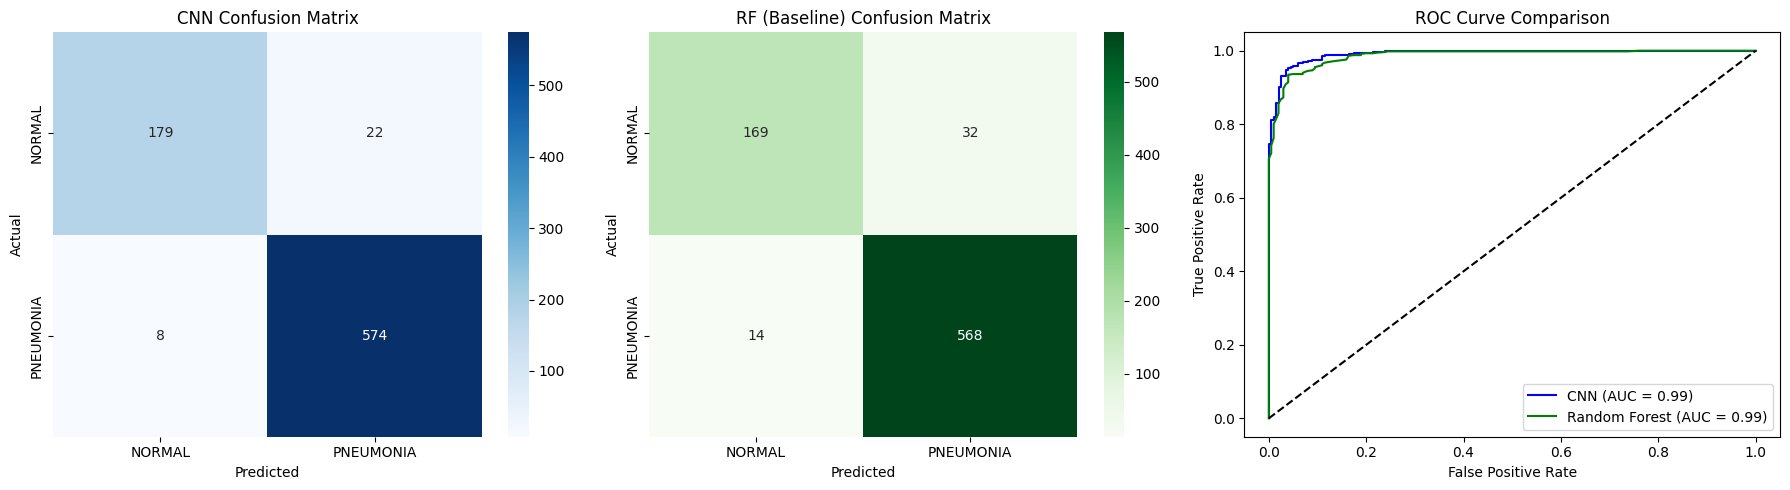

In [33]:
# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# CNN Confusion Matrix
cm_cnn = sklearn.metrics.confusion_matrix(y_test, cnn_preds)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            xticklabels=CLASSES, yticklabels=CLASSES)
axes[0].set_title('CNN Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# RF Confusion Matrix
cm_rf = sklearn.metrics.confusion_matrix(y_test, rf_preds)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], 
            xticklabels=CLASSES, yticklabels=CLASSES)
axes[1].set_title('RF (Baseline) Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# ROC Curves
fpr_cnn, tpr_cnn, _ = sklearn.metrics.roc_curve(y_test, cnn_probs)
fpr_rf, tpr_rf, _ = sklearn.metrics.roc_curve(y_test, rf_probs)

axes[2].plot(fpr_cnn, tpr_cnn, label=f'CNN (AUC = {sklearn.metrics.auc(fpr_cnn, tpr_cnn):.2f})', color='blue')
axes[2].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {sklearn.metrics.auc(fpr_rf, tpr_rf):.2f})', color='green')
axes[2].plot([0, 1], [0, 1], 'k--')
axes[2].set_title('ROC Curve Comparison')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].legend()

plt.tight_layout()
plt.show()

1. Feature Representation: The baseline classifier (Random Forest) relied on hand-crafted 
   statistical features (HOG for shapes/edges, LBP for texture, GLCM for contrast). The CNN 
   learned feature representations automatically through its convolutional layers, allowing 
   it to capture more complex spatial hierarchies.

2. Performance Comparison: The CNN clearly outperformed the traditional Random Forest model. 
   The CNN achieved 96.17% accuracy and 99.15% AUROC on the raw pixel data. while the Random Forest trained on extracted features achieved 94.13% accuracy 
   and a 98.63% AUROC. 

3. Misclassifications (False Negatives vs False Positives): 
   - False Negatives (Predicting Normal when it is Pneumonia) are highly dangerous in a medical 
     context because a sick patient gets sent home without treatment. 
   - False Positives (Predicting Pneumonia when Normal) cause unnecessary stress and further 
     testing, but are generally preferred over False Negatives. 
   - The CNN achieved an outstanding Recall of 98.63% compared to the RF's 97.59%. This means 
     the CNN is much better at minimizing False Negatives, making it the safe and
     reliable model for this automated diagnostic task.